# Discovery of Brown Dwarfs mining the 2MASS and SDSS databases with python

Created by **S. Orta¹, P. Mas-Buitrago², E. Solano²**

Last updated by **R. Murillo-Ojeda²** in November 2025

1. Facultad de Físicas. Universidad Complutense de Madrid.
2. Centro de Astrobiología (CAB), CSIC-INTA, Camino Bajo del Castillo s/n, 28692 Villanueva de la Cañada, Madrid, Spain. Spanish Virtual Observatory

This tutorial has been adapted from the "[Discovery of brown dwarfs mining the 2MASS and SDSS databases](https://cds-astro.github.io/tutorials/5_Brown_Dwarf_Search__Cross-matching_Catalogs.html)" jupyter notebook developed by the Strasbourg astronomical Data Center (CDS) team and the [SVO tutorial](https://zenodo.org/records/15058568)

For the tutorial to work correctly, the user must upload the "[requirements.txt](https://zenodo.org/records/15058568/files/requirements.txt?download=1)" file in their own Google Colab session. To do this, click on the "Files" icon on the left side of the page, select the "Upload to session storage" option (first icon in the pop-up menu) and upload the file from the local directory. Alternatively, the user can run the following cell.

In [ ]:
!wget -q -N https://raw.githubusercontent.com/spanish-virtual-observatory/svo-notebooks/main/tutorials_schools/requirements_aladin.txt

# **Introduction**



*   Scientific background: Brown dwarfs are objects occupying the gap between the least
massive stars and the most massive planets. They are intrinsically faint objects. Hence, their
detection is not straighforward and, in fact, was almost impossible until the advent of global
surveys at deep optical and near-infrared bands like SDSS, 2MASS or DENIS. We propose here to mine the 2MASS point source (2MASS-PSC) and the Sloan Digital Sky Survey (SDSS-DR16) catalogues to identify a T-type brown dwarf through an appropriate combination of colours in the optical and the infrared, an approach that perfectly fits into the Virtual Observatory.

These tasks include:
    
*   Obtaining data from the SDSS and 2MASS catalogues in a given sky region,
*   Crossmatching the results of these searches,
*   Filtering the resulting table using different photometric criteria, and
*   Confirming the brown dwarf nature of the found candidate.


We wil first install and import all the packages we will need, which can be found in the requirements file.

    











    


  



In [1]:
!pip install -q -r requirements_aladin.txt

In [2]:
# Standard Library
from pathlib import Path

# Astronomy tools
from astropy import units as u
from astropy.coordinates import Angle, SkyCoord

# Access astronomical databases
import pyvo
from astroquery.simbad import Simbad
from astroquery.vizier import Vizier
from astroquery.xmatch import XMatch

# Sky visualization
from ipyaladin import Aladin

import matplotlib.pyplot as plt
from mocpy import MOC, WCS
import warnings

Could not import regions, which is required for some of the functionalities of this module.


# **Step #1: Discovery**
  
  In this step, we will search 2MASS-PSC and SDSS-DR16 sources around RA:08h 30m
DEC:01d 30m with a 14 arcmin radius.

  * We will query both catalogues with [astroquery](https://astroquery.readthedocs.io/en/latest/). An alternative way of querying the catalogues using [pyVO](https://pyvo.readthedocs.io/en/latest/) and the TAP service of VizieR is described in the [CDS notebook](https://cds-astro.github.io/tutorials/5_Brown_Dwarf_Search__Cross-matching_Catalogs.html#introduction).
      
  * First we ask VizieR to show all the available catalogues.

  *   Then, we will select the catalogue in which we are interested for each source. This means II/246 for 2MASS-PSC and V/154 for SDSS-DR16.

  *   We will obtain a list of tables with just one table, so we print the first (and only) table of the list and select the columns which have the data we want to work with.


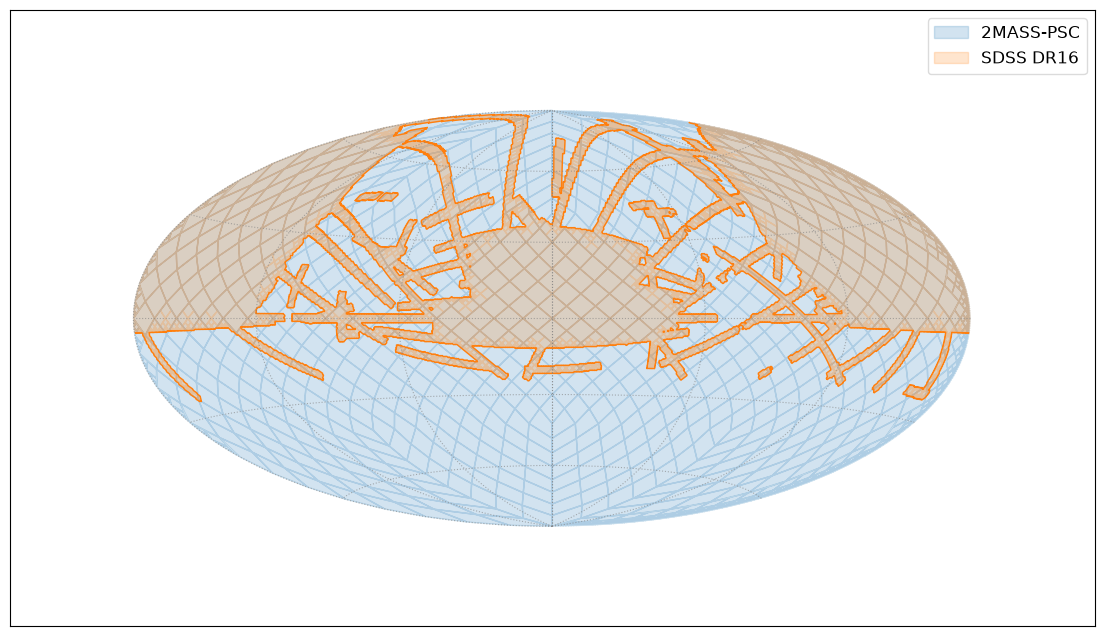

In [3]:
# Here we can see the area of the sky covered by each catalogue

moc_sdssdr12 = MOC.from_vizier_table('V/154/sdss16')
moc_mass = MOC.from_vizier_table('II/246/out')

fig = plt.figure(figsize=(14,8))

with WCS(fig,
         fov = 240*u.deg,
         center=SkyCoord(0,0,unit='deg',frame='icrs'),
         coordsys='icrs', rotation=Angle(0, u.degree),
         projection='AIT') as wcs:

    ax = fig.add_subplot(projection=wcs)

    moc_mass.fill(ax=ax, wcs=wcs, alpha=0.2, fill=True, color='#1f77b4', label='2MASS-PSC')
    moc_mass.border(ax=ax, wcs=wcs, color='#1f77b4', lw=1.)

    moc_sdssdr12.fill(ax=ax, wcs=wcs, alpha=0.2, fill=True, color='#ff7f0e', label='SDSS DR16')
    moc_sdssdr12.border(ax=ax, wcs=wcs, color='#ff7f0e', lw=1.)



ax.legend(fontsize=12, loc='upper right', framealpha=0.7)
plt.grid(color='gray', linestyle='dotted', linewidth=0.8, alpha=0.6)

plt.show()
warnings.filterwarnings('ignore')

In [4]:
# We start searching the 2MASS catalogues available at VizieR

catalog_list_2mass = Vizier.find_catalogs("2MASS")

for catalog_ID, catalog in catalog_list_2mass.items():
    print(catalog_ID, ": ", catalog.description)

II/246 :  2MASS All-Sky Catalog of Point Sources (Cutri+ 2003)
II/281 :  2MASS 6X Point Source Working Database / Catalog (Cutri+ 2006)
VII/233 :  2MASS All-Sky Extended Source Catalog (XSC) (IPAC/UMass, 2003-2006)


In [5]:
# As mentioned above, we are interested in the 2MASS-PSC, which is in the catalogue II/246 in VizieR
Vizier.get_catalogs("II/246")

TableList with 1 tables:
	'0:II/246/out' with 15 column(s) and 50 row(s) 

In [6]:
# We make the query in 2MASS-PSC keeping only the needed columns

custom_vizier = Vizier(
    row_limit=-1,
    columns=["2MASS","RAJ2000", "DEJ2000", "Jmag", "Hmag", "Kmag"],
)

coord = SkyCoord(ra="08:30:00", dec="01:30:00", unit=(u.hourangle, u.deg))
mass_psc = custom_vizier.query_region(coord, radius=14 * u.arcmin, catalog="II/246")

mass_psc[0][:5]

2MASS,RAJ2000,DEJ2000,Jmag,Hmag,Kmag
,deg,deg,mag,mag,mag
str17,float64,float64,float32,float32,float32
08300340+0116389,127.514167,1.277495,16.553,16.179,15.894
08300219+0116090,127.509154,1.269173,15.963,15.546,14.930
08300186+0116223,127.507779,1.272875,15.594,15.563,15.272
08295118+0116188,127.463251,1.271903,15.844,15.110,15.029
08295112+0117110,127.463023,1.286400,14.093,13.652,13.553


*   Now we query SDSS DR16 following the same steps




In [7]:
# Now we search the SDSS catalogues available in VizieR

catalog_list_sdss = Vizier.find_catalogs("SDSS")

for catalog_ID, catalog in catalog_list_sdss.items():
    print(catalog_ID, ": ", catalog.description)

II/294 :  The SDSS Photometric Catalog, Release 7 (Adelman-McCarthy+, 2009)
V/139 :  The SDSS Photometric Catalog, Release 9 (Adelman-McCarthy+, 2012)
V/147 :  The SDSS Photometric Catalogue, Release 12 (Alam+, 2015)
V/154 :  Sloan Digital Sky Surveys (SDSS), Release 16 (DR16) (Ahumada+, 2020)
VII/289 :  SDSS quasar catalog, sixteenth data release (DR16Q) (Lyke+, 2020)


In [8]:
Vizier.get_catalogs("V/154")

TableList with 1 tables:
	'0:V/154/sdss16' with 28 column(s) and 50 row(s) 

In [9]:
# We make the query in SDSS DR16 keeping only the needed columns

custom_vizier = Vizier(
    row_limit=-1,
    columns=["objID","RA_ICRS", "DE_ICRS","class", "umag", "gmag"],
)

coord = SkyCoord(ra="08:30:00", dec="01:30:00", unit=(u.hourangle, u.deg))

sdss_results = custom_vizier.query_region(coord, radius=14 * u.arcmin, catalog="V/154")
sdss_results[0][:5]

objID,RA_ICRS,DE_ICRS,class,umag,gmag
,deg,deg,,mag,mag
int64,float64,float64,uint8,float32,float32
1237646798677147984,127.507769,1.272848,6,18.371,17.224
1237646798677147985,127.507767,1.272843,6,18.379,17.225
1237646798677148312,127.509294,1.269172,6,23.623,20.933
1237646798677148313,127.509292,1.269167,6,24.270,20.938
1237646798677148314,127.509292,1.269167,6,24.270,20.938



  # **Step #2: Cross-matching**
    
*   In the next step we will find common sources in the 2MASS-PSC and SDSS-DR16 catalogues. One simple way to do this using the CDS XMatch service, which can also be reached with [astroquery](https://astroquery.readthedocs.io/en/latest/xmatch/xmatch.html). We will proceed by uploading one of the tables and crossmatching it to a table available in VizieR. A 4 arcsec search radius will be used.
                                    

In [10]:
mass_psc[0].write("2MASS_PSC.vot", format="votable", overwrite=True)
sdss_results[0].write("SDSS_DR16.vot", format="votable", overwrite=True)

In [11]:
mass_sdss = XMatch.query(
    cat1=Path("2MASS_PSC.vot").open(),
    cat2="vizier:V/154/sdss16",
    max_distance=4 * u.arcsec,
    colRA1="RAJ2000",
    colDec1="DEJ2000")

#mass_sdss
# Convert to Astropy Table
from astropy.table import Table
mass_sdss = Table(mass_sdss)

# Sort by angular distance
mass_sdss.sort('angDist')

# Filter by the nearest neighbour
unique_sources = []
nearest_rows = []

for row in mass_sdss:
    ra = row['RAJ2000']  # Identificador de la fuente en 2MASS_PSC

    if ra not in unique_sources:
      unique_sources.append(ra)
      nearest_rows.append(row)

# Convert the filtered list into a new table, keeping only the columns of interest
mass_sdss_nearest = Table(rows=nearest_rows, names=mass_sdss.colnames)["angDist", "2MASS", "RAJ2000", "DEJ2000",
                                        "Jmag", "Hmag", "Kmag", "objID", "class",
                                        "RA_ICRS", "DE_ICRS", "umag", "gmag"]


# Show 'umag','gmag' with just two decimals
mass_sdss_nearest["umag"] = mass_sdss_nearest["umag"].round(decimals=2)
mass_sdss_nearest["gmag"] = mass_sdss_nearest["gmag"].round(decimals=2)

# Show a subset of rows and all columns

mass_sdss_nearest[:5]

angDist,2MASS,RAJ2000,DEJ2000,Jmag,Hmag,Kmag,objID,class,RA_ICRS,DE_ICRS,umag,gmag
float64,str16,float64,float64,float32,float32,float32,int64,uint8,float64,float64,float64,float64
0.001891,08294333+0130351,127.430561,1.50976,11.134,10.85,10.777,1237654599942865010,6,127.430561,1.50976,14.91,13.06
0.001932,08295398+0128527,127.474941,1.481328,13.613,13.329,13.268,1237653622299557922,6,127.474941,1.481328,16.3,15.22
0.00273,08302987+0135163,127.624477,1.587864,12.74,12.426,12.385,1237654599942930691,6,127.624478,1.587864,15.39,14.14
0.003382,08303173+0132451,127.632209,1.545872,13.654,13.244,13.279,1237653622299623604,6,127.63221,1.545872,16.84,15.3
0.005606,08291832+0125595,127.326353,1.433212,15.093,14.689,14.679,1237646798677082346,0,127.326352,1.433213,--,--


In [12]:
print(f"We are currently working with {len(mass_sdss_nearest)} sources")

We are currently working with 682 sources


 # **Step #3: Filtering**

*   In this step we will first select point sources using the SDSS flag (class=6). "class" is a column of the SDSS DR16 catalog that provides information on the type of object (3=galaxy, 6=star).

*   Then, we select sources with no detection in the u,g SDSS bands (u > 22.0 && g >22.2, since brown dwarfs are cool objects not detected in the blue SDSS bands) and sources fulfilling the brown dwarf criteria provided by
Burgasser et al. (2000, Apj, 531, L57): ((J-H)<0.3 && (H- K)<0.3).


   


In [13]:
# Keep only the sources classified as stars in SDSS DR16 (class=6)

index_stars = (mass_sdss_nearest["class"] == 6 )
mass_sdss_nearest = mass_sdss_nearest[index_stars]

print(f"We have {len(mass_sdss_nearest)} stars")

mass_sdss_nearest[:5]

We have 625 stars


angDist,2MASS,RAJ2000,DEJ2000,Jmag,Hmag,Kmag,objID,class,RA_ICRS,DE_ICRS,umag,gmag
float64,str16,float64,float64,float32,float32,float32,int64,uint8,float64,float64,float64,float64
0.001891,08294333+0130351,127.430561,1.50976,11.134,10.85,10.777,1237654599942865010,6,127.430561,1.50976,14.91,13.06
0.001932,08295398+0128527,127.474941,1.481328,13.613,13.329,13.268,1237653622299557922,6,127.474941,1.481328,16.3,15.22
0.00273,08302987+0135163,127.624477,1.587864,12.74,12.426,12.385,1237654599942930691,6,127.624478,1.587864,15.39,14.14
0.003382,08303173+0132451,127.632209,1.545872,13.654,13.244,13.279,1237653622299623604,6,127.63221,1.545872,16.84,15.3
0.005671,08293054+0140259,127.377259,1.67387,15.241,14.736,14.966,1237654604237635810,6,127.37726,1.673869,18.05,16.73


In [14]:
# We now extract the sources that match the colours conditions specified above

# Add columns with J-H and H-K colour
mass_sdss_nearest["J-H"] = mass_sdss_nearest["Jmag"] - mass_sdss_nearest["Hmag"]
mass_sdss_nearest["H-K"] = mass_sdss_nearest["Hmag"] - mass_sdss_nearest["Kmag"]

# We take a look at the colour
index_bd = (mass_sdss_nearest["umag"] > 22.0) \
    & (mass_sdss_nearest["gmag"] > 22.2) \
    & (mass_sdss_nearest["J-H"] < 0.3) \
    & (mass_sdss_nearest["H-K"] < 0.3)

candidates = mass_sdss_nearest[index_bd]

print(f"We have {len(candidates)} candidates for Brown Dwarfs")
candidates

We have 1 candidates for Brown Dwarfs


angDist,2MASS,RAJ2000,DEJ2000,Jmag,Hmag,Kmag,objID,class,RA_ICRS,DE_ICRS,umag,gmag,J-H,H-K
float64,str16,float64,float64,float32,float32,float32,int64,uint8,float64,float64,float64,float64,float32,float32
0.320283,08304878+0128311,127.703265,1.47532,16.289,16.14,16.358,1237654599942997338,6,127.703345,1.47528,25.61,25.52,0.14900017,-0.21800041


# **Step #4: Visualization**

  *   The ipyaladin package allows to run Aladin Lite in the notebook. As with any instance of Aladin Lite you can zoom in and out by scrolling your mouse. In the top left corner of the widget, you may chose which survey to look at, add layers, search for sources, …





In [ ]:
aladin1 = Aladin(
    survey="P/UKIDSS/LAS/J1",
    fov=0.03, #Change this parameter to adjust the initial Field of View
    target="{:.4f} {:.4f}".format(candidates["RAJ2000"][0], candidates["DEJ2000"][0]),
)
aladin1

*   You can also add tables to the widget by:



In [ ]:
aladin1.add_table(candidates, name="candidates")

If you now click on the small square indicating the location of the source, the widget will show the corresponding table values in the lower part of the widget. As you can see, the source is slightly shifted from the predicted position due to its proper motion (the blue square position refers to 2MASS epoch while the image is at UKIDSS epoch).

# **Step #5: Check in Simbad**

Let's see now if the found source is included in Simbad and, if so, how it has been labelled.

In [ ]:
# First candidate has an index 0 in the table
customSimbad = Simbad()
customSimbad.add_votable_fields("otype")

candidate_coord = SkyCoord(
    ra=candidates["RAJ2000"][0],
    dec=candidates["DEJ2000"][0],
    unit=u.deg,
)

candidate_simbad1 = customSimbad.query_region(candidate_coord, radius=10 * u.arcsec)

candidate_simbad1['ra'] = candidate_simbad1['ra'].round(decimals=4)
candidate_simbad1['dec'] = candidate_simbad1['dec'].round(decimals=4)

candidate_simbad1

We see how our candidate is labelled in Simbad as "otype=BD*", which confirms it brown dwarf nature.

If we now want to see in which papers the Brown Dwarf 2MASS J08304878+0128311 was included, we may use the following query in Simbad.

In [17]:
tap_simbad = pyvo.dal.TAPService("https://simbad.cds.unistra.fr/simbad/sim-tap")

query = """
SELECT BIBCode, Journal, Title, "year", Volume,
       Page || '-' || Last_Page AS "Pages", DOI
FROM ref JOIN has_ref ON oidbibref = oidbib
         JOIN ident ON has_ref.oidref = ident.oidref
WHERE id = '2MASS J08304878+0128311'
ORDER BY "year" DESC;
"""

result = tap_simbad.search(query).to_table()
result

bibcode,journal,title,year,volume,Pages,doi
object,object,object,int16,int32,object,object
2025AJ....170...43T,AJ,A Survey of Model Fits to Brown Dwarf Spectra Through the L-T Sequence.,2025,170,,10.3847/1538-3881/adda2a
2025ApJ...992...93Z,ApJ,Classifying Cool Dwarfs: Comprehensive Spectral Typing of Field and Peculiar Dwarfs Using Machine Learning.,2025,992,,10.3847/1538-4357/adfb7d
2023A&A...670A..19G,A&A,The Fifth Catalogue of Nearby Stars (CNS5).,2023,670,,10.1051/0004-6361/202244250
2021AJ....161...42B,AJ,"A volume-limited sample of ultracool dwarfs. I. Construction, space density, and a gap in the L/T transition.",2021,161,42-42,10.3847/1538-3881/abc893
2020AJ....159..257B,AJ,The Hawaii infrared parallax program. IV. A comprehensive parallax survey of L0-T8 dwarfs with UKIRT.,2020,159,257-257,10.3847/1538-3881/ab84f4
2016ApJ...827...25B,ApJ,The orbit of the L dwarf + T dwarf spectral binary SDSS J080531.84+481233.0.,2016,827,25-25,10.3847/0004-637X/827/1/25
2016A&A...589A..49S,A&A,Photometric brown-dwarf classification. II. A homogeneous sample of 1361 L and T dwarfs brighter than J = 17.5 with accurate spectral types.,2016,589,49-49,10.1051/0004-6361/201527359
2016ApJ...817..112S,ApJ,A proper motion survey using the first sky pass of NEOWISE-reactivation data.,2016,817,,10.3847/0004-637X/817/2/112
2015ApJ...810..158F,ApJ,Fundamental parameters and spectral energy distributions of young and field age objects with masses spanning the stellar to planetary regime.,2015,810,,10.1088/0004-637X/810/2/158
